Производная функции при решении прикладных задач далеко не всегда может быть вычислена аналитически. Как миниммум потому, что зачастую в машинном обучении сама функция, для которой надо вычислять производную неизвестна, есть лишь возможность расчитать её значения в каких-то конкретных точках.

Конечно, специаилизрованные библиотеки могут рассчитывать занчения производной несмотря на такие сложности. В numpy для этого есть готовая функция.

Однако одно из важных умений для специалиста в области машинного обучения - умение находить простые математические идеи для решения, казалось бы, нерешаемых задач. Такие методы решения, которые не используют аналитического решения, обычно называются "численными".

Рассмотрим численное решение для задачи взятия производной.

# Простейшее численное решение задачи расчёта значения производной

Производная, как известно, это наклон касательной. При этом мы не знаем уравнения касательной, но значем значение во всех точек сетки соответствующего пространства.

В таком случае значение угла наклона (касательной) вычисляется очень просто:
$$k = \frac{\Delta y}{\Delta x}$$

При этом для расчёта всего набора значений необходимо взять сетку значений, по которой мы и будем считать. Формула расчёта значения производной $f(x)$ в этом случае становится немного другой, но это лишь технические изменения.

$$f'(x) = \frac{f(x+h) - f(x-h)}{2h}$$

Этот метод называется методом центральной разности.

Разности можно брать и немного иначе, например так (правые разности):
$$ f'(x_i) = \frac{f(x_{i+1}) - f(x_i)} {h}$$

Но этот метод менее точен.

# Задание
Напишите программный код, который реализует расчёт значений производной обоими методами и сравнит его с тем, что рассчитывает numpy.

Обратие внимание, что взятие разности приводит к уменьшению размерности полученного ряда значений производной. Придумайте, как исправить возникаюущую проблему.

Ниже представлена визуализация, которая позволит увидеть на практие результат работы вашего метода.

In [ ]:
# df_forward - расчёт правых разностей
# df_central - расчёт центральных разностей
# df_numpy - расчёт с помощью numpy
# f(x) - любая ваша функция
# df_exact(x) - аналитически рассчитанная производная вашей функции


In [2]:
import numpy as np
import matplotlib.pyplot as plt

def f(x):
    return np.sin(x)

def df_exact(x):
    return np.cos(x)

N = 40
x = np.linspace(0, 2*np.pi, N)
h = x[1] - x[0]
y = f(x)

df_forward = np.empty_like(y)
df_forward[:-1] = (y[1:] - y[:-1]) / h
df_forward[-1]  = (y[-1] - y[-2]) / h  


df_central = np.empty_like(y)
df_central[1:-1] = (y[2:] - y[:-2]) / (2 * h)
df_central[0]    = (y[1] - y[0]) / h           
df_central[-1]   = (y[-1] - y[-2]) / h

df_numpy = np.gradient(y, h)

err_forward = np.abs(df_forward - df_exact(x))
err_central = np.abs(df_central - df_exact(x))

print(f"\nМакс. ошибка правой разности:   {err_forward.max():.6f}")
print(f"Макс. ошибка центральной разности: {err_central.max():.6f}")
print(f"Во сколько раз центральная точнее:  "
      f"{err_forward.max() / err_central.max():.1f}")




Макс. ошибка правой разности:   0.080488
Макс. ошибка центральной разности: 0.004320
Во сколько раз центральная точнее:  18.6


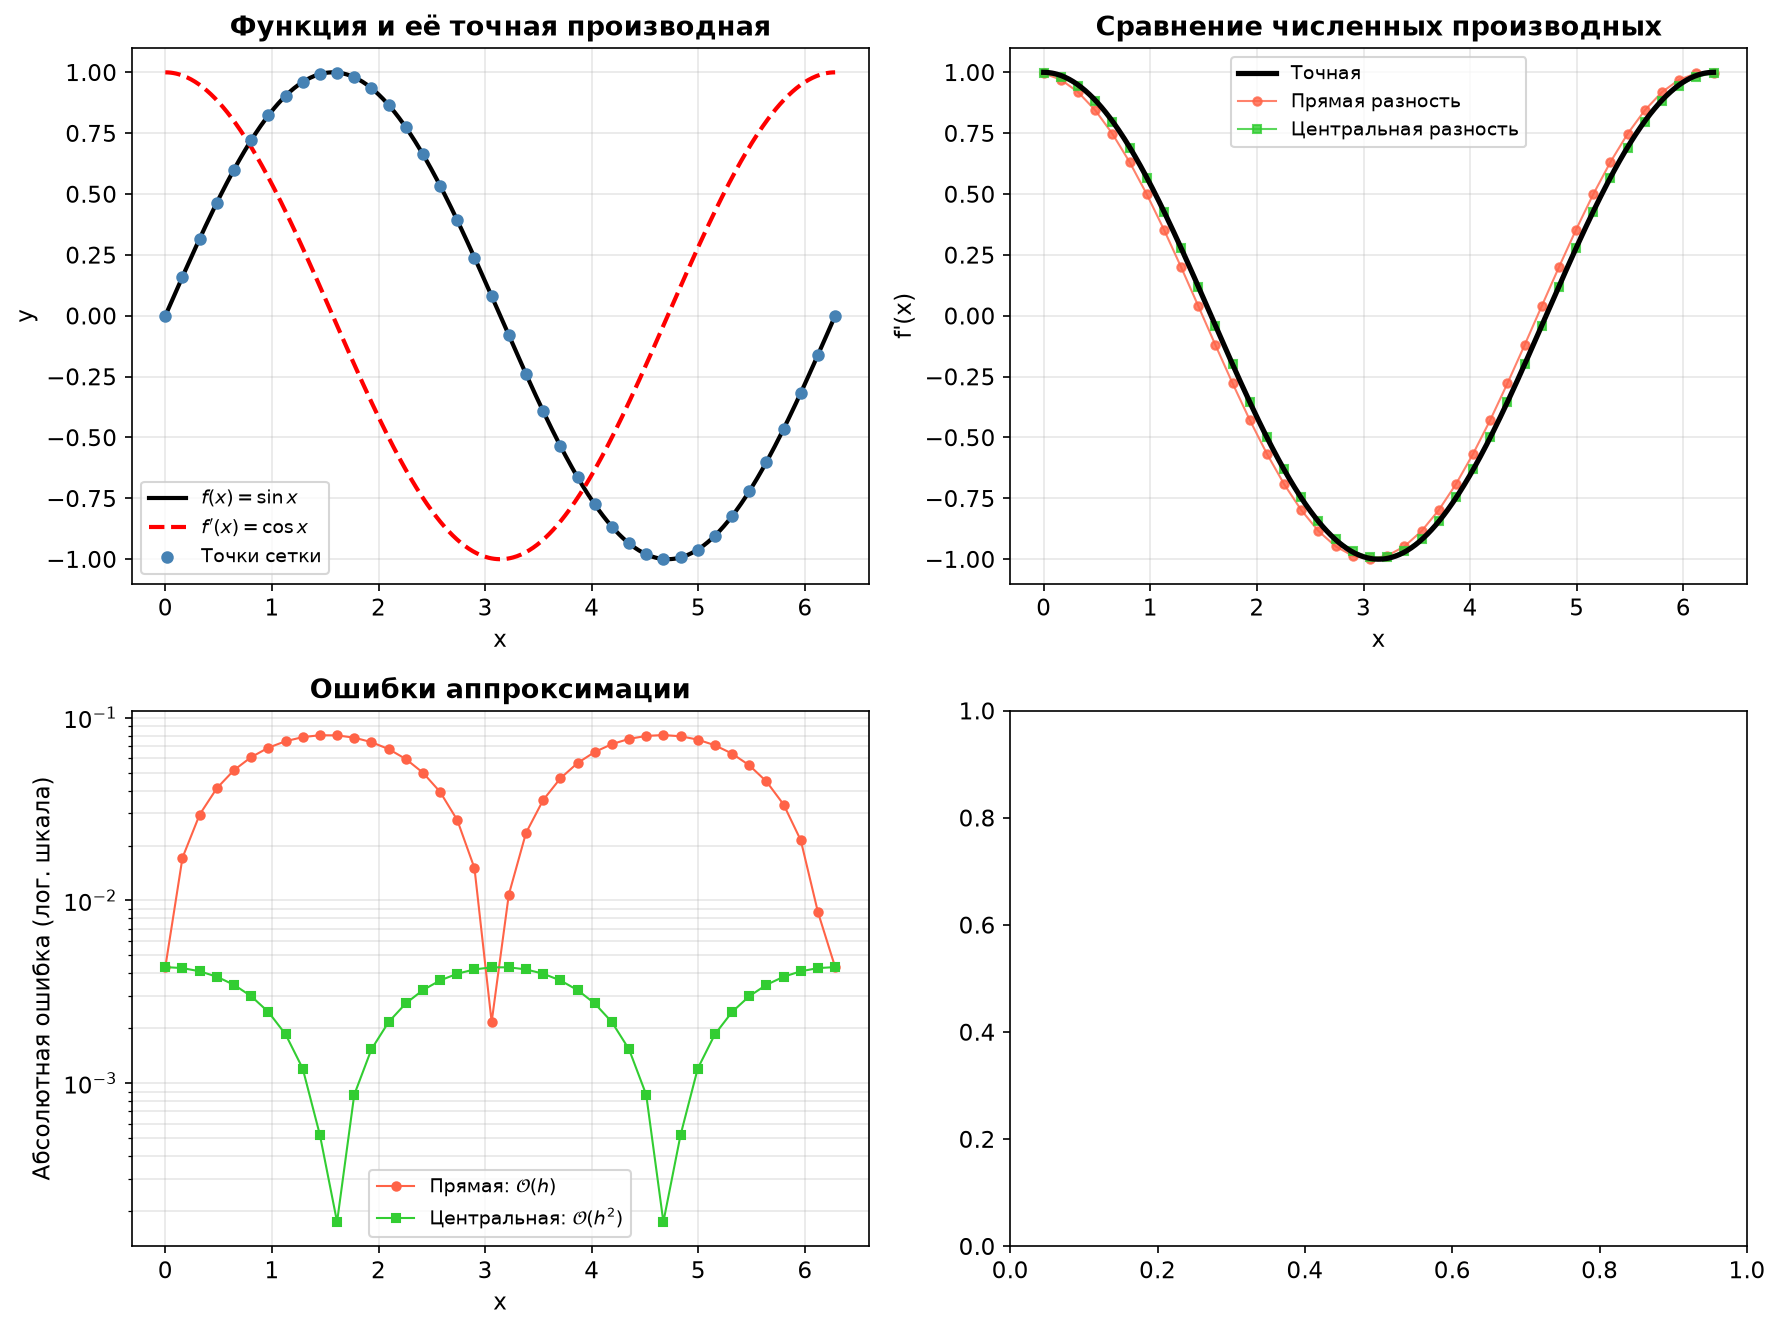

In [3]:
#  Визуализация

plt.rcParams.update({
    "figure.dpi": 150,
    "font.size": 11,
    "axes.titlesize": 13,
    "axes.titleweight": "bold",
    "legend.fontsize": 9,
})

fig, axes = plt.subplots(2, 2, figsize=(12, 9))

ax = axes[0, 0]
x_fine = np.linspace(0, 2 * np.pi, 500)

ax.plot(x_fine, f(x_fine), "k-", lw=2, label=r"$f(x) = \sin x$")
ax.plot(x_fine, df_exact(x_fine), "r--", lw=2, label=r"$f'(x) = \cos x$")
ax.scatter(x, y, color="steelblue", zorder=5, s=25, label="Точки сетки")
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_title("Функция и её точная производная")
ax.legend()
ax.grid(True, alpha=0.3)

ax = axes[0, 1]

ax.plot(x_fine, df_exact(x_fine), "k-", lw=2.5, label="Точная", zorder=4)
ax.plot(x, df_forward, "o-", color="tomato", ms=4, lw=1,
        label="Прямая разность", alpha=0.8)
ax.plot(x, df_central, "s-", color="limegreen", ms=4, lw=1,
        label="Центральная разность", alpha=0.8)
ax.set_xlabel("x")
ax.set_ylabel("f'(x)")
ax.set_title("Сравнение численных производных")
ax.legend()
ax.grid(True, alpha=0.3)

ax = axes[1, 0]

ax.semilogy(x, err_forward, "o-", color="tomato", ms=4, lw=1,
            label=r"Прямая: $\mathcal{O}(h)$")
ax.semilogy(x, err_central + 1e-16, "s-", color="limegreen", ms=4, lw=1,
            label=r"Центральная: $\mathcal{O}(h^2)$")

ax.set_xlabel("x")
ax.set_ylabel("Абсолютная ошибка (лог. шкала)")
ax.set_title("Ошибки аппроксимации")
ax.legend()
ax.grid(True, which="both", alpha=0.3)


plt.tight_layout()
plt.savefig("derivative_visualization.png")
plt.show()